In [1]:
#load datasets
import pickle
import numpy as np
import matplotlib.pyplot as plt

with open("data.pkl","rb") as f:
    data=pickle.load(f)

X=np.asarray(data["x"],dtype=float)
y=np.asarray(data["y"],dtype=int)

print("Feature shape:",X.shape)
print("Label shape:",y.shape)
print("Classes and counts:",np.unique(y,return_counts=True))

Feature shape: (20000, 16)
Label shape: (20000,)
Classes and counts: (array([0, 1]), array([10000, 10000]))


In [2]:

# train, test, validation
from math import log, sqrt, cos, sin, pi

seed = 42

# Linear Congruential Generator (LCG)
def random_number():
    global seed
    seed = (1664525 * seed + 1013904223) % (2**32)
    return seed / (2**32)


# Box-Muller Transform
def box_muller():
    u1 = random_number()
    u2 = random_number()

    while u1 == 0:
        u1 = random_number()

    z1 = sqrt(-2 * log(u1)) * cos(2 * pi * u2)
    z2 = sqrt(-2 * log(u1)) * sin(2 * pi * u2)

    return np.array([z1, z2])


def custom_shuffle(idx):
    idx = list(idx)

    for i in range(len(idx) - 1, 0, -1):
        j = int(random_number() * (i + 1))
        idx[i], idx[j] = idx[j], idx[i]

    return np.array(idx, dtype=int)


def stratified_split(X, y, test_size=0.15, val_size=0.15):

    train_idx = []
    val_idx = []
    test_idx = []

    for c in np.unique(y):

        idx = np.where(y == c)[0]

        idx = custom_shuffle(idx)

        n_test = int(len(idx) * test_size)
        n_val = int(len(idx) * val_size)

        test_idx.extend(idx[:n_test])

        val_idx.extend(
            idx[n_test:n_test+n_val]
        )

        train_idx.extend(
            idx[n_test+n_val:]
        )

    train_idx = custom_shuffle(train_idx)
    val_idx = custom_shuffle(val_idx)
    test_idx = custom_shuffle(test_idx)

    return (
        X[train_idx], X[val_idx], X[test_idx],
        y[train_idx], y[val_idx], y[test_idx]
    )


X_train, X_val, X_test, y_train, y_val, y_test = stratified_split(X, y)


print("Training samples:", len(y_train))
print("Validation samples:", len(y_val))
print("Testing samples:", len(y_test))

print("Training class counts:",np.unique(y_train, return_counts=True))

print("Validation class counts:",np.unique(y_val, return_counts=True))

print("Testing class counts:",np.unique(y_test, return_counts=True))


Training samples: 14000
Validation samples: 3000
Testing samples: 3000
Training class counts: (array([0, 1]), array([7000, 7000]))
Validation class counts: (array([0, 1]), array([1500, 1500]))
Testing class counts: (array([0, 1]), array([1500, 1500]))


Explained variance ratio for each PC:
[0.1573 0.1511 0.1152 0.0888 0.0731 0.0651 0.0594 0.0566 0.0506 0.0369
 0.033  0.0284 0.026  0.0243 0.0197 0.0143]
Cumulative explained variance:
[0.1573 0.3084 0.4237 0.5125 0.5856 0.6507 0.7101 0.7668 0.8173 0.8543
 0.8873 0.9157 0.9417 0.966  0.9857 1.    ]
Number of components required for 95% variance: 14
Cumulative explained variance: 96.6 %


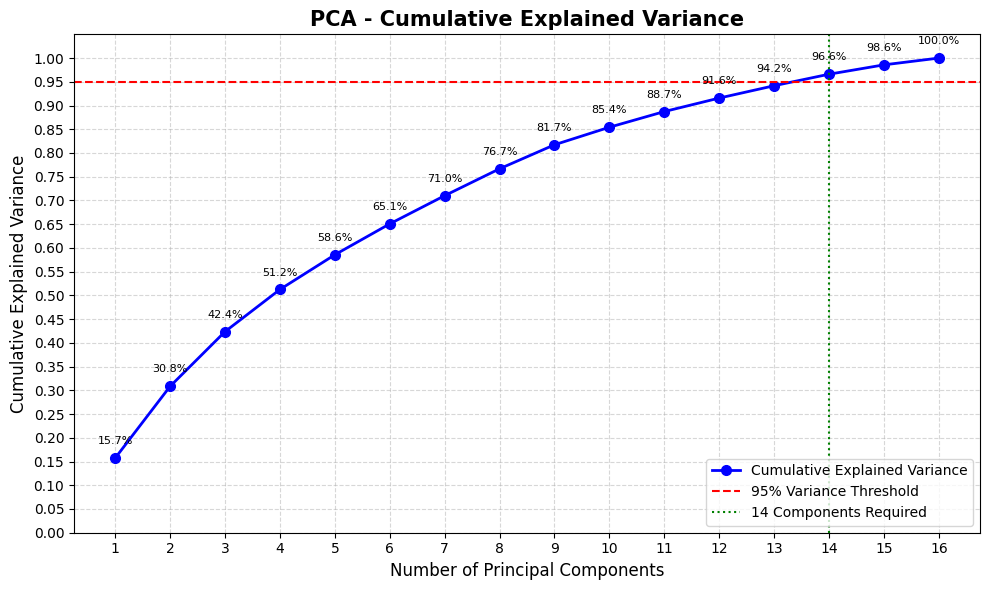

In [3]:
class PCA:
    def __init__(self,n_components):
        self.n_components=n_components
    def fit(self,X):
        self.mean_=X.mean(axis=0)
        X_centered=X-self.mean_
        cov=np.cov(X_centered,rowvar=False)
        values,vectors=np.linalg.eigh(cov)
        order=np.argsort(values)[::-1]
        values=values[order]
        vectors=vectors[:,order]
        self.components_=vectors[:,:self.n_components]
        self.explained_variance_ratio_=values[:self.n_components]/np.sum(values)
        return self
    def transform(self,X):
        return (X-self.mean_)@self.components_
    def fit_transform(self,X):
        return self.fit(X).transform(X)

pca_full=PCA(16).fit(X_train)
print("Explained variance ratio for each PC:")
print(np.round(pca_full.explained_variance_ratio_,4))
print("Cumulative explained variance:")
print(np.round(np.cumsum(pca_full.explained_variance_ratio_),4))

import numpy as np
import matplotlib.pyplot as plt

cumulative_variance = np.cumsum(
    pca_full.explained_variance_ratio_
)

n_components_95 = np.argmax(cumulative_variance >= 0.95) + 1

plt.figure(figsize=(10, 6))

plt.plot(
    range(1, len(cumulative_variance) + 1),
    cumulative_variance,
    marker='o',
    markersize=7,
    color='blue',
    linewidth=2,
    label='Cumulative Explained Variance'
)

plt.axhline(
    y=0.95,
    color='red',
    linestyle='--',
    linewidth=1.5,
    label='95% Variance Threshold'
)

plt.axvline(
    x=n_components_95,
    color='green',
    linestyle=':',
    label=f'{n_components_95} Components Required'
)

for i, value in enumerate(cumulative_variance):
    plt.annotate(
        f'{value * 100:.1f}%',
        (i + 1, value),
        textcoords="offset points",
        xytext=(0, 10),
        ha='center',
        fontsize=8
    )

plt.xlabel("Number of Principal Components", fontsize=12)
plt.ylabel("Cumulative Explained Variance", fontsize=12)

plt.title(
    "PCA - Cumulative Explained Variance",
    fontsize=15,
    fontweight='bold'
)

plt.xticks(range(1, len(cumulative_variance) + 1))
plt.yticks(np.arange(0, 1.05, 0.05))
plt.ylim(0, 1.05)

plt.grid(True, linestyle='--', alpha=0.5)
plt.legend(loc='lower right')

print("Number of components required for 95% variance:",n_components_95)

print("Cumulative explained variance:",
      round(cumulative_variance[n_components_95 - 1] * 100, 2), "%")

plt.tight_layout()
plt.show()


In [4]:


def logsumexp(a, axis=1):
    m = np.max(a, axis=axis, keepdims=True)
    return np.squeeze(m, axis=axis) + np.log(
        np.sum(np.exp(a - m), axis=axis)
    )


class GMM:

    def __init__(self, n_components=3, max_iter=40,
                 reg=1e-5, seed=42):
        self.n_components = n_components
        self.max_iter = max_iter
        self.reg = reg
        self.seed = seed

    def _log_gaussian(self, X, mean, cov):
        d = X.shape[1]

        sign, logdet = np.linalg.slogdet(cov)

        if sign <= 0:
            cov = cov + 1e-3 * np.eye(d)
            sign, logdet = np.linalg.slogdet(cov)

        inv = np.linalg.inv(cov)
        diff = X - mean

        quad = np.sum((diff @ inv) * diff, axis=1)

        return -0.5 * (
            d * np.log(2 * np.pi) + logdet + quad
        )

    def _kkt_weights(self, nk):

        k = len(nk)
        weights = np.zeros(k)

        total = np.sum(nk)

        for j in range(k):
            if nk[j] > 0:
                weights[j] = nk[j] / total

        weights = np.maximum(weights, 0)
        weights /= np.sum(weights)

        return weights

    def fit(self, X):

        rng = np.random.default_rng(self.seed)

        n, d = X.shape
        k = self.n_components

        self.weights_ = np.ones(k) / k

        self.means_ = X[
            rng.choice(n, k, replace=False)
        ].copy()

        base_cov = (
            np.cov(X, rowvar=False)
            + self.reg * np.eye(d)
        )

        self.covariances_ = np.array([
            base_cov.copy() for _ in range(k)
        ])

        for iteration in range(self.max_iter):

            log_prob = np.column_stack([
                np.log(self.weights_[j] + 1e-12)
                + self._log_gaussian(
                    X,
                    self.means_[j],
                    self.covariances_[j]
                )
                for j in range(k)
            ])

            log_norm = logsumexp(log_prob, axis=1)

            resp = np.exp(
                log_prob - log_norm[:, None]
            )

            nk = resp.sum(axis=0) + 1e-10

            self.weights_ = self._kkt_weights(nk)

            self.means_ = (resp.T @ X) / nk[:, None]

            new_cov = []

            for j in range(k):

                diff = X - self.means_[j]

                cov = (
                    diff.T @ (diff * resp[:, j, None])
                ) / nk[j]

                cov += self.reg * np.eye(d)

                new_cov.append(cov)

            self.covariances_ = np.array(new_cov)

        return self

    def score_samples(self, X):

        parts = np.column_stack([
            np.log(self.weights_[j] + 1e-12)
            + self._log_gaussian(
                X,
                self.means_[j],
                self.covariances_[j]
            )
            for j in range(self.n_components)
        ])

        return logsumexp(parts, axis=1)


class GMMClassifier:

    def __init__(self, n_components=3, max_iter=40):
        self.n_components = n_components
        self.max_iter = max_iter

    def fit(self, X, y):

        self.classes_ = np.unique(y)
        self.models_ = []

        for c in self.classes_:

            model = GMM(
                n_components=self.n_components,
                max_iter=self.max_iter,
                seed=42 + int(c)
            )

            model.fit(X[y == c])

            self.models_.append(model)

        return self

    def predict(self, X):

        scores = np.column_stack([
            model.score_samples(X)
            for model in self.models_
        ])

        return self.classes_[
            np.argmax(scores, axis=1)
        ]


# ---------------------------------
# Train GMM Classifier with KKT
# ---------------------------------

model = GMMClassifier(
    n_components=3,
    max_iter=40
)

model.fit(X_train, y_train)


y_val_pred = model.predict(X_val)


accuracy = np.mean(y_val_pred == y_val) * 100

print("Validation Accuracy:", accuracy, "%")


Validation Accuracy: 100.0 %


In [5]:
class LDA:
    def fit(self,X,y):
        self.classes_=np.unique(y)
        self.means_=[]
        d=X.shape[1]
        Sw=np.zeros((d,d))
        for c in self.classes_:
            Xc=X[y==c]
            mean=Xc.mean(axis=0)
            self.means_.append(mean)
            diff=Xc-mean
            Sw+=diff.T@diff
        Sw=Sw/(len(X)-len(self.classes_))
        Sw+=1e-6*np.eye(d)
        self.means_=np.asarray(self.means_)
        self.priors_=np.array([np.mean(y==c) for c in self.classes_])
        self.inv_cov_=np.linalg.inv(Sw)
        return self
    def predict(self,X):
        scores=[]
        for i,c in enumerate(self.classes_):
            mean=self.means_[i]
            score=X@self.inv_cov_@mean-0.5*mean@self.inv_cov_@mean+np.log(self.priors_[i])
            scores.append(score)
        return self.classes_[np.argmax(np.column_stack(scores),axis=1)]



# Train LDA
lda = LDA()
lda.fit(X_train, y_train)

# Predictions
y_val_pred = lda.predict(X_val)

# Accuracy
print("Validation Accuracy:", np.mean(y_val_pred == y_val)*100, "%")





Validation Accuracy: 91.2 %


In [6]:
class KNN:
    def __init__(self,k=5,batch_size=100):
        self.k=k
        self.batch_size=batch_size
    def fit(self,X,y):
        self.X_train=X
        self.y_train=y
        return self
    def predict(self,X):
        predictions=[]
        train_sq=np.sum(self.X_train**2,axis=1)
        for start in range(0,len(X),self.batch_size):
            batch=X[start:start+self.batch_size]
            distances=np.sum(batch**2,axis=1)[:,None]+train_sq[None,:]-2*batch@self.X_train.T
            nearest=np.argpartition(distances,self.k-1,axis=1)[:,:self.k]
            for row in nearest:
                labels=self.y_train[row]
                values,counts=np.unique(labels,return_counts=True)
                predictions.append(values[np.argmax(counts)])
        return np.asarray(predictions)
    
model = KNN(k=5, batch_size=100)
model.fit(X_train, y_train)

y_val_pred = model.predict(X_val)

print("Validation Accuracy:", np.mean(y_val_pred == y_val)*100, "%")




Validation Accuracy: 99.66666666666667 %


In [7]:
class LinearSVM:
    def __init__(self,learning_rate=0.05,epochs=400,C=1.0):
        self.learning_rate=learning_rate
        self.epochs=epochs
        self.C=C
    def fit(self,X,y):
        self.classes_=np.unique(y)
        y_binary=np.where(y==self.classes_[1],1.0,-1.0)
        n,d=X.shape
        self.w_=np.zeros(d)
        self.b_=0.0
        for epoch in range(self.epochs):
            margins=y_binary*(X@self.w_+self.b_)
            active=margins<1
            grad_w=self.w_-self.C*(X[active].T@y_binary[active])/n
            grad_b=-self.C*np.sum(y_binary[active])/n
            rate=self.learning_rate/(1+0.01*epoch)
            self.w_-=rate*grad_w
            self.b_-=rate*grad_b
        return self
    def predict(self,X):
        return np.where(X@self.w_+self.b_>=0,self.classes_[1],self.classes_[0])

model = LinearSVM(learning_rate=0.05, epochs=400, C=1.0)
model.fit(X_train, y_train)

y_val_pred = model.predict(X_val)

print("Validation Accuracy:", np.mean(y_val_pred == y_val)*100, "%")





Validation Accuracy: 90.96666666666667 %


In [8]:
def accuracy_score(y_true,y_pred):
    return np.mean(y_true==y_pred)*100

def confusion_matrix_manual(y_true,y_pred):
    classes=np.unique(np.concatenate([y_true,y_pred]))
    matrix=np.zeros((len(classes),len(classes)),dtype=int)
    for i,a in enumerate(classes):
        for j,b in enumerate(classes):
            matrix[i,j]=np.sum((y_true==a)&(y_pred==b))
    return classes,matrix

def evaluate_all(Xtr,Xte,ytr,yte,verbose=True):
    models={
        "GMM":GMMClassifier(n_components=3,max_iter=40),
        "LDA":LDA(),
        "K-NN":KNN(k=5,batch_size=100),
        "SVM":LinearSVM(learning_rate=0.05,epochs=400,C=1.0)
    }
    results={}
    predictions={}
    trained_models={}

    for name,model in models.items():
        model.fit(Xtr,ytr)
        pred=model.predict(Xte)
        acc=accuracy_score(yte,pred)
        results[name]=acc
        predictions[name]=pred
        trained_models[name]=model

        if verbose:
            print(name,"accuracy:",round(acc,2),"%")

    return results,predictions,trained_models

validation accuracy
GMM accuracy: 100.0 %
LDA accuracy: 91.2 %
K-NN accuracy: 99.67 %
SVM accuracy: 90.97 %
test accuracy
GMM accuracy: 99.97 %
LDA accuracy: 91.57 %
K-NN accuracy: 99.5 %
SVM accuracy: 91.03 %

========== VALIDATION CONFUSION MATRICES ==========

 GMM
[[1500    0]
 [   0 1500]]

 LDA
[[1367  133]
 [ 131 1369]]

 K-NN
[[1492    8]
 [   2 1498]]

 SVM
[[1359  141]
 [ 130 1370]]


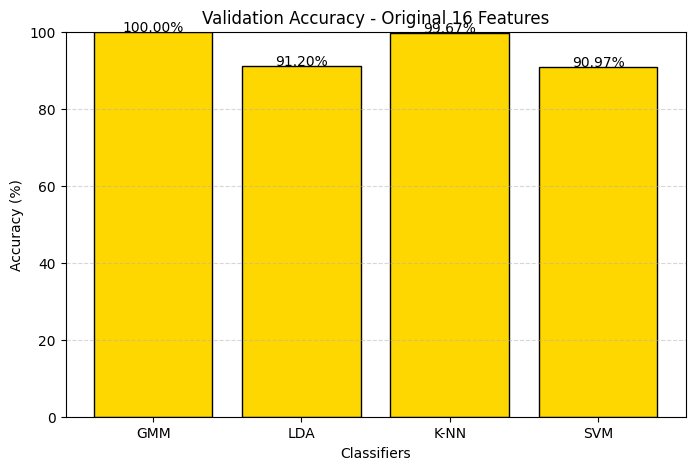

In [9]:

print("validation accuracy")
val_results,val_predictions,trained_models=evaluate_all(X_train,X_val,y_train,y_val)
print("test accuracy")
test_results,test_predictions,model=evaluate_all(X_train,X_test,y_train,y_test)
print("\n========== VALIDATION CONFUSION MATRICES ==========")

for name, pred in val_predictions.items():
    classes, cm = confusion_matrix_manual(y_val, pred)

    print("\n", name)
    print(cm)

plt.figure(figsize=(8,5))
plt.bar(val_results.keys(),val_results.values(),color="gold",edgecolor="black")
plt.title("Validation Accuracy - Original 16 Features")
plt.xlabel("Classifiers")
plt.ylabel("Accuracy (%)")
plt.ylim(0,100)
plt.grid(axis="y",linestyle="--",alpha=0.5)

for i,v in enumerate(val_results.values()):
 plt.text(i,v+0.1,f"{v:.2f}%",ha="center")

plt.show()


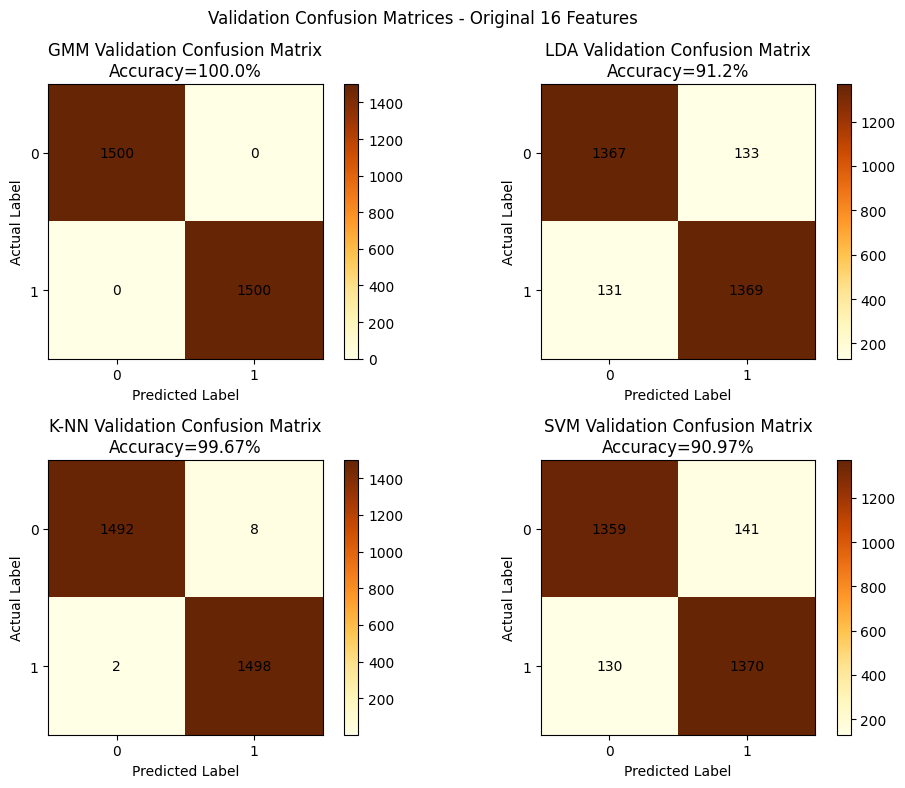

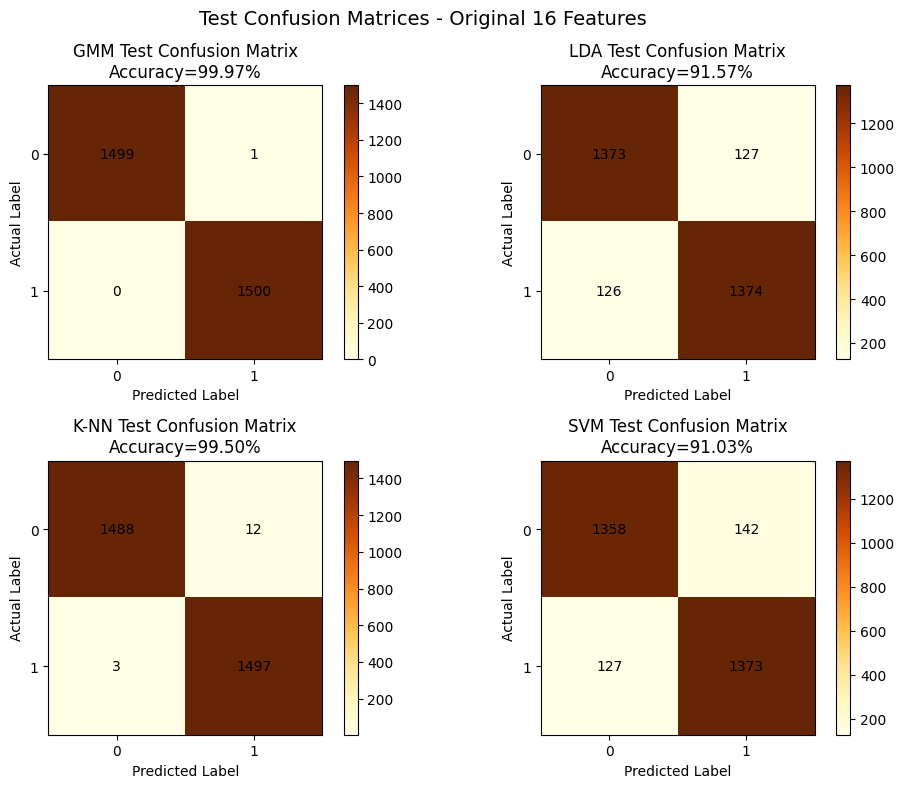

In [10]:
fig,axes=plt.subplots(2,2,figsize=(10,8))
axes=axes.flatten()

for ax,(name,pred) in zip(axes,val_predictions.items()):
    classes,cm=confusion_matrix_manual(y_val,pred)
    acc=accuracy_score(y_val,pred)

    im=ax.imshow(cm,cmap="YlOrBr")
    ax.set_title(name+" Validation Confusion Matrix\nAccuracy="+str(round(acc,2))+"%")
    ax.set_xlabel("Predicted Label")
    ax.set_ylabel("Actual Label")

    ax.set_xticks(range(len(classes)))
    ax.set_yticks(range(len(classes)))
    ax.set_xticklabels(classes)
    ax.set_yticklabels(classes)

    for i in range(2):
        for j in range(2):
            ax.text(j,i,cm[i,j],ha="center",va="center")

    fig.colorbar(im,ax=ax)

fig.suptitle("Validation Confusion Matrices - Original 16 Features")
plt.tight_layout()
plt.show()
fig,axes=plt.subplots(2,2,figsize=(10,8))
axes=axes.flatten()

for ax,(name,pred) in zip(axes,test_predictions.items()):
    classes,cm=confusion_matrix_manual(y_test,pred)
    acc=accuracy_score(y_test,pred)

    im=ax.imshow(cm,cmap="YlOrBr")
    ax.set_title(f"{name} Test Confusion Matrix\nAccuracy={acc:.2f}%")
    ax.set_xlabel("Predicted Label")
    ax.set_ylabel("Actual Label")

    ax.set_xticks(range(len(classes)))
    ax.set_yticks(range(len(classes)))
    ax.set_xticklabels(classes)
    ax.set_yticklabels(classes)

    for i in range(len(classes)):
        for j in range(len(classes)):
            ax.text(j,i,cm[i,j],ha="center",va="center")

    fig.colorbar(im,ax=ax)

plt.suptitle("Test Confusion Matrices - Original 16 Features",fontsize=14)
plt.tight_layout()
plt.show()

In [11]:
def calculate_metrics(y_true,y_pred):
 classes,cm=confusion_matrix_manual(y_true,y_pred)
 precision=[]
 recall=[]
 f1=[]
 for i in range(len(classes)):
  tp=cm[i,i]
  fp=np.sum(cm[:,i])-tp
  fn=np.sum(cm[i,:])-tp
  p=tp/(tp+fp) if tp+fp>0 else 0
  r=tp/(tp+fn) if tp+fn>0 else 0
  f=2*p*r/(p+r) if p+r>0 else 0
  precision.append(p)
  recall.append(r)
  f1.append(f)
 print("Accuracy:",round(accuracy_score(y_true,y_pred),2),"%")
 print("Precision:",round(np.mean(precision),4))
 print("Recall:",round(np.mean(recall),4))
 print("F1-score:",round(np.mean(f1),4))


========== FINAL TEST METRICS ==========

 GMM
Accuracy: 99.97 %
Precision: 0.9997
Recall: 0.9997
F1-score: 0.9997

 LDA
Accuracy: 91.57 %
Precision: 0.9157
Recall: 0.9157
F1-score: 0.9157

 K-NN
Accuracy: 99.5 %
Precision: 0.995
Recall: 0.995
F1-score: 0.995

 SVM
Accuracy: 91.03 %
Precision: 0.9104
Recall: 0.9103
F1-score: 0.9103


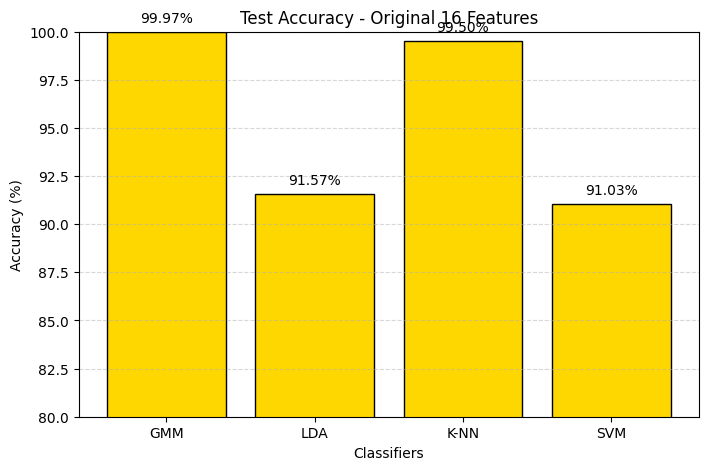

In [12]:
print("\n========== FINAL TEST METRICS ==========")
for name,pred in test_predictions.items():
 print("\n",name)
 calculate_metrics(y_test,pred)
plt.figure(figsize=(8,5))
plt.bar(test_results.keys(),test_results.values(),color="gold",edgecolor="black")
plt.title("Test Accuracy - Original 16 Features")
plt.xlabel("Classifiers")
plt.ylabel("Accuracy (%)")
plt.ylim(80,100)
plt.grid(axis="y",linestyle="--",alpha=0.5)
for i,v in enumerate(test_results.values()):
 plt.text(i,v+0.5,f"{v:.2f}%",ha="center")
plt.show()

In [13]:
component_values=[2,5,10,16]

pca_results={}
pca_models={}
all_predictions={}
all_trained_models={}

# Original 16 features
print("\n========== ORIGINAL 16 FEATURES ==========")

val_result,predictions,models=evaluate_all(
    X_train,X_val,y_train,y_val
)

pca_results["Original 16"]=val_result
all_predictions["Original 16"]=predictions
baseline_models=models.copy()
all_trained_models["Original 16"]=models.copy()

# PCA features
for k in component_values:
    pca=PCA(n_components=k).fit(X_train)

    Xtr_pca=pca.transform(X_train)
    Xval_pca=pca.transform(X_val)

    explained_variance=np.sum(pca.explained_variance_ratio_)*100

    print("\nPCA components:",k)
    print("Cumulative explained variance:",round(explained_variance,2),"%")

    val_result,predictions,models=evaluate_all(
        Xtr_pca,Xval_pca,y_train,y_val
    )

    pca_results[f"PCA {k}"]=val_result
    pca_models[k]=pca
    all_predictions[f"PCA {k}"]=predictions
    all_trained_models[f"PCA {k}"]=models.copy()


========== ORIGINAL 16 FEATURES ==========
GMM accuracy: 100.0 %
LDA accuracy: 91.2 %
K-NN accuracy: 99.67 %
SVM accuracy: 90.97 %

PCA components: 2
Cumulative explained variance: 30.84 %
GMM accuracy: 85.8 %
LDA accuracy: 85.0 %
K-NN accuracy: 84.17 %
SVM accuracy: 82.97 %

PCA components: 5
Cumulative explained variance: 58.56 %
GMM accuracy: 93.13 %
LDA accuracy: 88.27 %
K-NN accuracy: 91.8 %
SVM accuracy: 87.6 %

PCA components: 10
Cumulative explained variance: 85.43 %
GMM accuracy: 99.3 %
LDA accuracy: 90.47 %
K-NN accuracy: 98.27 %
SVM accuracy: 90.2 %

PCA components: 16
Cumulative explained variance: 100.0 %
GMM accuracy: 100.0 %
LDA accuracy: 91.2 %
K-NN accuracy: 99.67 %
SVM accuracy: 91.43 %


In [14]:
classifier_names = ["GMM", "LDA", "K-NN", "SVM"]

print(f'{"Features":<20}', end="")

for name in classifier_names:
    print(f'{name:>18}', end="")

print("\n" + "-" * 92)

for feature_name, result in pca_results.items():

    print(f'{feature_name:<20}', end="")

    for name in classifier_names:
        print(f'{result[name]:>17.2f}%', end="")

    print()

Features                           GMM               LDA              K-NN               SVM
--------------------------------------------------------------------------------------------
Original 16                    100.00%            91.20%            99.67%            90.97%
PCA 2                           85.80%            85.00%            84.17%            82.97%
PCA 5                           93.13%            88.27%            91.80%            87.60%
PCA 10                          99.30%            90.47%            98.27%            90.20%
PCA 16                         100.00%            91.20%            99.67%            91.43%


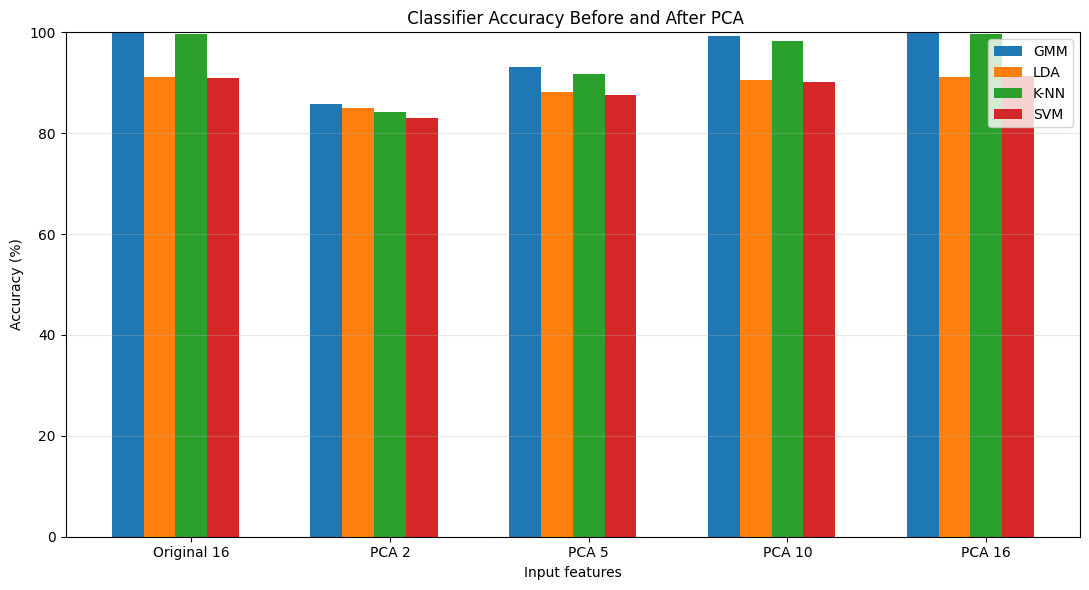

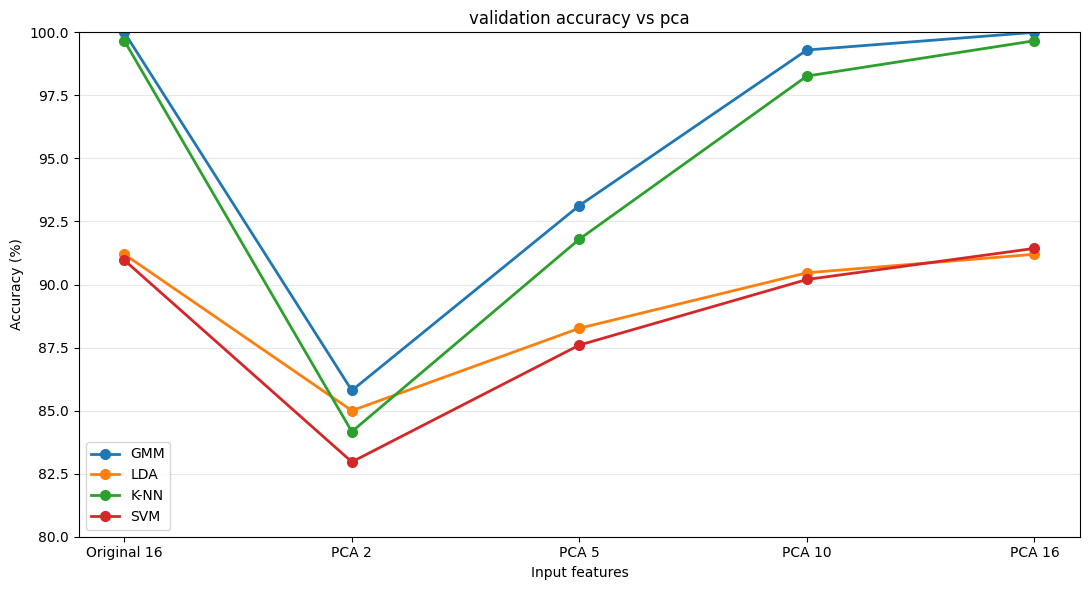

In [15]:
labels=list(pca_results.keys())
x=np.arange(len(labels))
width=0.16

plt.figure(figsize=(11,6))
for i,name in enumerate(classifier_names):
    values=[pca_results[label][name] for label in labels]
    plt.bar(x+(i-2)*width,values,width,label=name)

plt.xticks(x,labels)
plt.ylabel("Accuracy (%)")
plt.xlabel("Input features")
plt.title(" Classifier Accuracy Before and After PCA")
plt.ylim(0,100)
plt.legend()
plt.grid(axis="y",alpha=0.3)
plt.tight_layout()
plt.show()
plt.figure(figsize=(11,6))

for name in classifier_names:
    values = [pca_results[label][name] for label in labels]
    plt.plot(labels, values, marker='o', linewidth=2, markersize=7, label=name)

plt.ylabel("Accuracy (%)")
plt.xlabel("Input features")
plt.title("validation accuracy vs pca")
plt.ylim(80,100)
plt.legend()
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()


In [16]:
for feature_name,result in pca_results.items():
    best=max(result,key=result.get)
    print(feature_name,": best classifier =",best,"with",round(result[best],2),"% accuracy")



Original 16 : best classifier = GMM with 100.0 % accuracy
PCA 2 : best classifier = GMM with 85.8 % accuracy
PCA 5 : best classifier = GMM with 93.13 % accuracy
PCA 10 : best classifier = GMM with 99.3 % accuracy
PCA 16 : best classifier = GMM with 100.0 % accuracy


In [17]:
import pandas as pd

pca_test_results={}
pca_test_predictions={}

print("\n========== ORIGINAL 16 FEATURES TESTING ==========")

original_predictions={}

for name,model in baseline_models.items():
    pred=model.predict(X_test)
    original_predictions[name]=pred
    acc=np.mean(y_test==pred)*100
    pca_test_results.setdefault("Original 16",{})[name]=acc

for k in component_values:
    print("\n========== PCA",k,"TESTING ==========")

    Xtest_pca=pca_models[k].transform(X_test)

    pca_test_predictions[f"PCA {k}"]={}
    pca_test_results[f"PCA {k}"]={}

    models=all_trained_models[f"PCA {k}"]

    for name,model in models.items():
        pred=model.predict(Xtest_pca)
        pca_test_predictions[f"PCA {k}"][name]=pred
        acc=np.mean(y_test==pred)*100
        pca_test_results[f"PCA {k}"][name]=acc

test_table=pd.DataFrame(pca_test_results).T
test_table.index.name="Features"
test_table.columns.name="Classifier"

print("\n========== FINAL TEST ACCURACY TABLE ==========")
print(test_table.round(2).to_string())
best_accuracy=-1
best_features=""
best_classifier=""

for features,results in pca_test_results.items():
    for classifier,accuracy in results.items():
        if accuracy>best_accuracy:
            best_accuracy=accuracy
            best_features=features
            best_classifier=classifier

print("\n========== BEST TEST ACCURACY ==========")
print("Best Features:",best_features)
print("Best Classifier:",best_classifier)
print("Best Test Accuracy:",round(best_accuracy,2),"%")


========== ORIGINAL 16 FEATURES TESTING ==========

========== PCA 2 TESTING ==========

========== PCA 5 TESTING ==========

========== PCA 10 TESTING ==========

========== PCA 16 TESTING ==========

========== FINAL TEST ACCURACY TABLE ==========
Classifier     GMM    LDA   K-NN    SVM
Features                               
Original 16  99.97  91.57  99.50  91.03
PCA 2        84.67  83.93  82.90  82.03
PCA 5        92.57  87.60  91.37  87.20
PCA 10       98.90  89.33  97.97  89.43
PCA 16       99.97  91.57  99.50  91.70

========== BEST TEST ACCURACY ==========
Best Features: Original 16
Best Classifier: GMM
Best Test Accuracy: 99.97 %


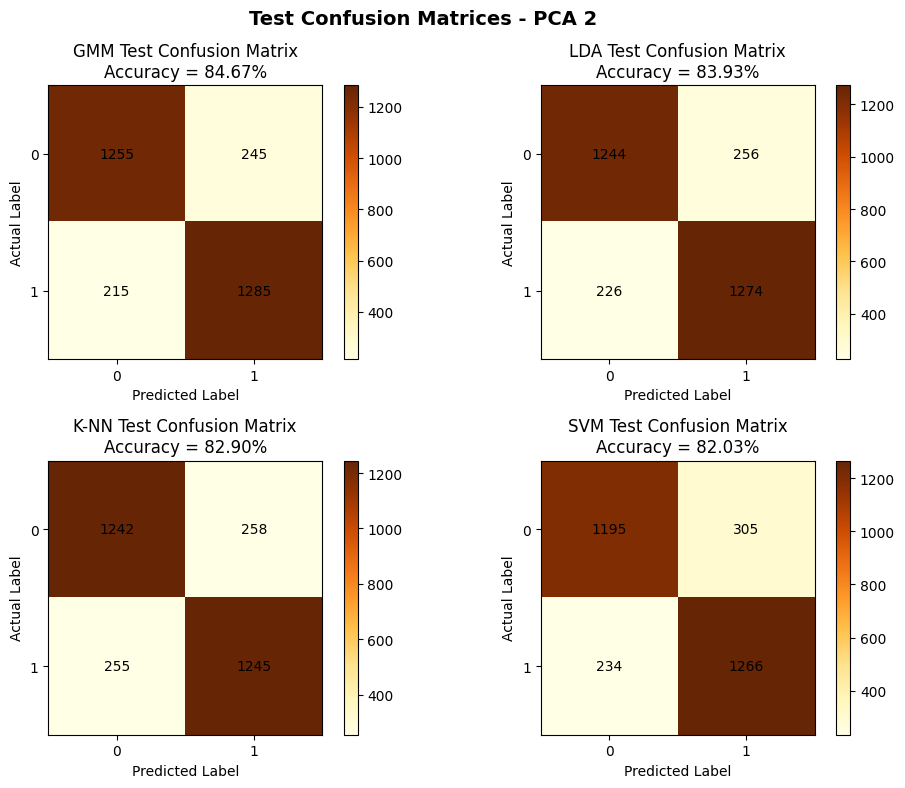

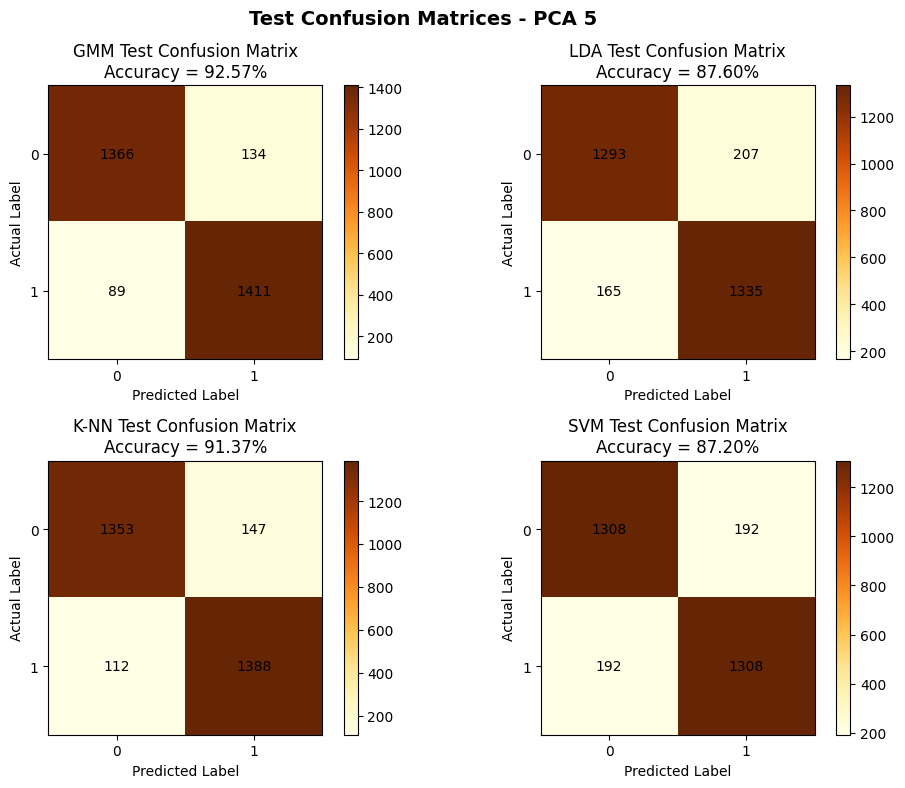

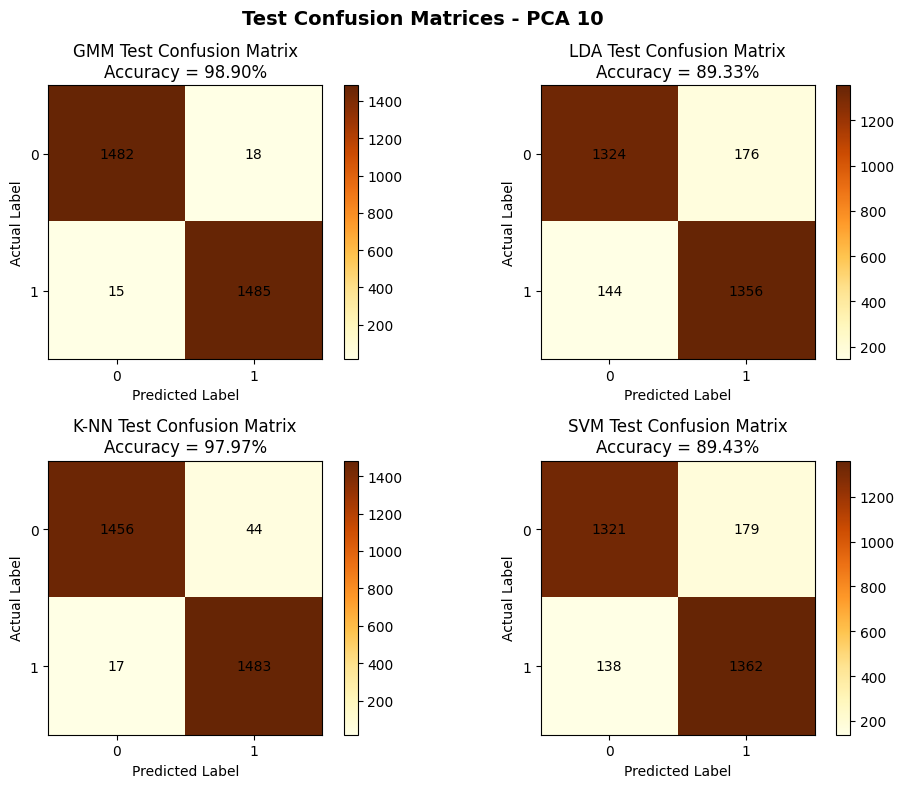

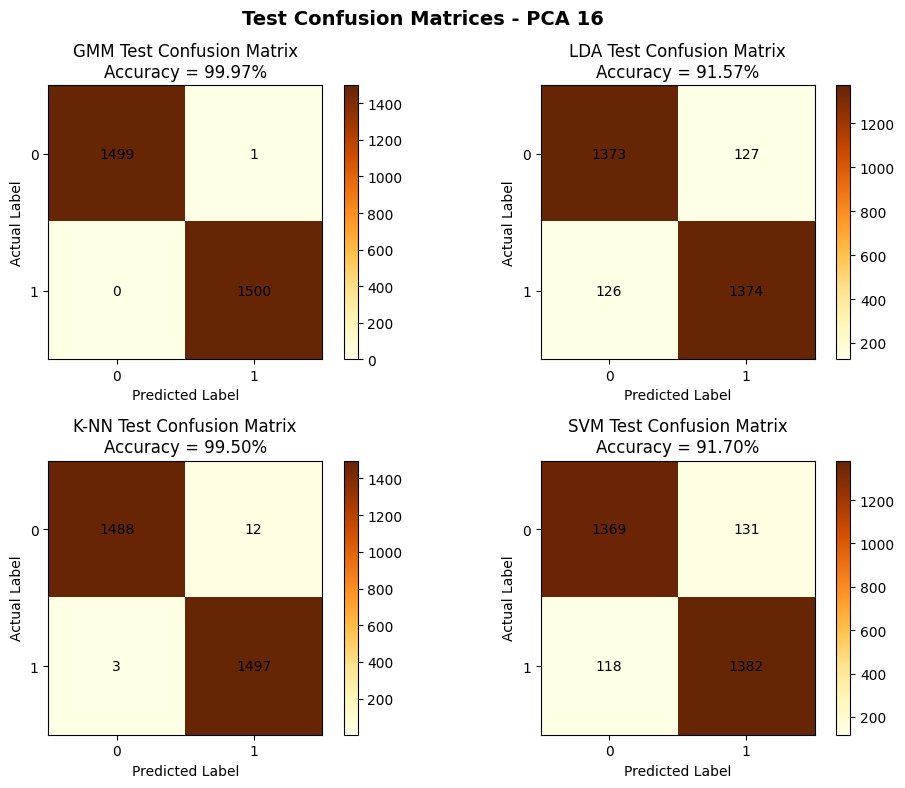

In [19]:
for fs, preds in pca_test_predictions.items():

    fig, axes = plt.subplots(2, 2, figsize=(10, 8))
    axes = axes.flatten()

    for ax, (name, pred) in zip(axes, preds.items()):

        classes, cm = confusion_matrix_manual(y_test, pred)
        acc = accuracy_score(y_test, pred) 

        im = ax.imshow(cm, cmap="YlOrBr")

        ax.set_title(f"{name} Test Confusion Matrix\nAccuracy = {acc:.2f}%")
        ax.set_xlabel("Predicted Label")
        ax.set_ylabel("Actual Label")

        ax.set_xticks(range(len(classes)))
        ax.set_yticks(range(len(classes)))
        ax.set_xticklabels(classes)
        ax.set_yticklabels(classes)

        for i in range(len(classes)):
            for j in range(len(classes)):
                ax.text(j, i, cm[i, j], ha="center", va="center")

        fig.colorbar(im, ax=ax)

    fig.suptitle(
        f"Test Confusion Matrices - {fs}",
        fontsize=14,
        fontweight="bold"
    )

    plt.tight_layout()
    plt.show()